In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### load pipe

In [2]:
import pickle

with open('pipe.pkl', 'rb') as f:
    cross, T = pickle.load(f)

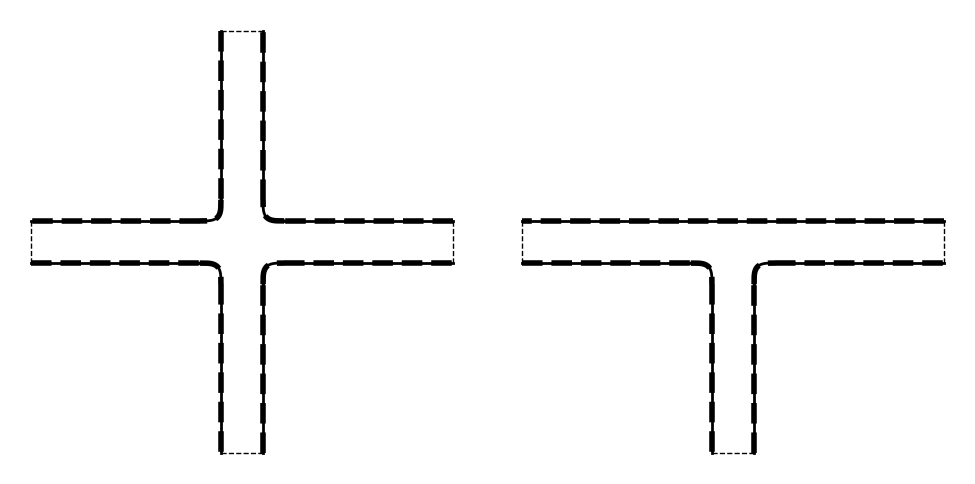

In [3]:
# Visualize the pipe geometries using the boundary plotting method
fig, axes = plt.subplots(1,2, figsize=(10,5) , tight_layout=True,sharey=True)

# Plot T-shaped pipe
axes[0].set_aspect('equal')
axes[0].axis('off')
cross.exterior_boundary.plot_plyg_bdr(axes[0],color='k')

axes[1].set_aspect('equal')
axes[1].axis('off')
T.exterior_boundary.plot_plyg_bdr(axes[1],color='k')

plt.show()

#### assembling the pipes

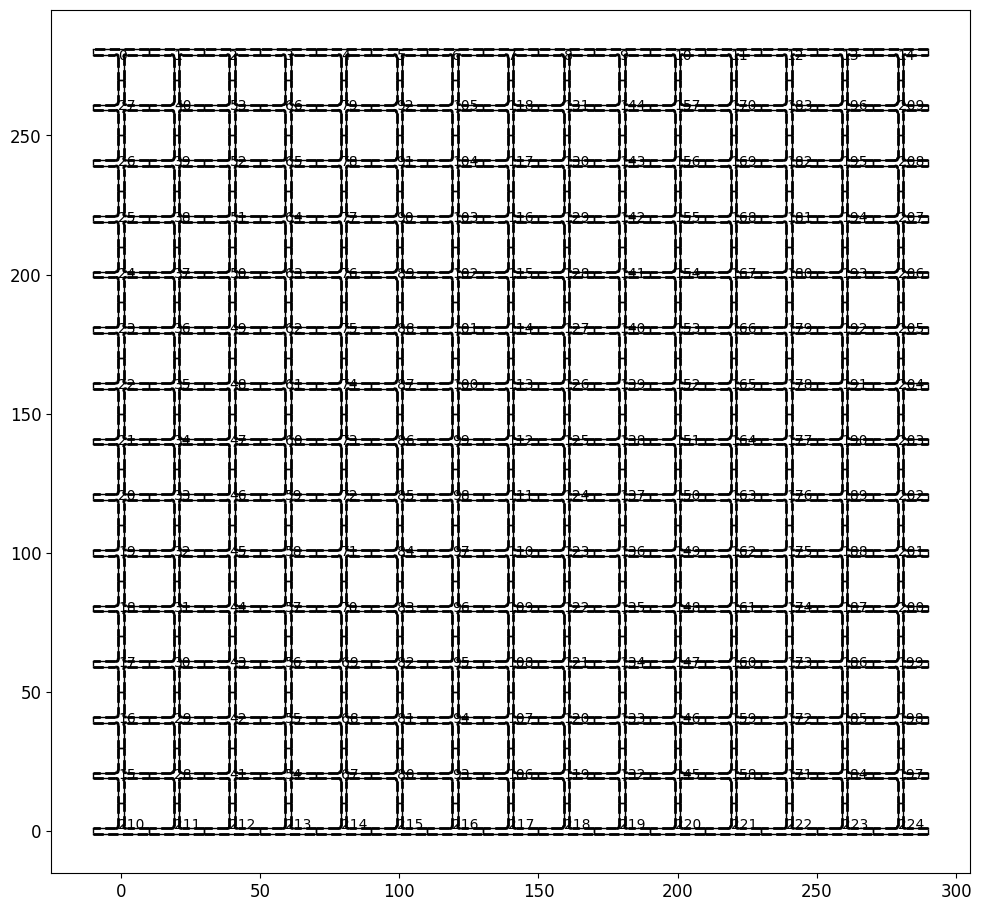

In [4]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

n_rep_x = 15
n_rep_y = 15


middle_pipes = [RealPipe(cross,20*i,20*j,0) for i in range(n_rep_x) for j in range(1,n_rep_y-1)]
bottom_pipes = [RealPipe(T,20*i,20*0,np.pi) for i in range(n_rep_x)]
top_pipes = [RealPipe(T,20*i,20*(n_rep_y-1),0) for i in range(n_rep_x)]

pipes = top_pipes + middle_pipes + bottom_pipes

for i,pipe in enumerate(pipes):
    pipe.plot_plyg_bdr(ax)
    x = np.mean(pipe.xs)-1
    y = np.mean(pipe.ys)-1
    ax.text(x,y,f'{i}',fontsize=10,color='k')

ax.set_aspect('equal')
# ax.axis('off')
plt.show()

#### re-development of the pipe-system solver 

fundamental variables: 
- the coefficients of characteristic flows of all pipes

fundamental constraints:
- pressure is path-irrelavent
- flux is preserved at each connection

boundary conditions (imposed by users):
- either pressures at each boundary 
- or flux at each boundary


nodes are the connection point or boundary let. 

In [5]:
flows = []
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        flows.append((ip,iflow))
flows = list(enumerate(flows))
flows_idx2flow = dict(flows)
flow2flows_idx = {flow:idx for idx,flow in flows}

In [6]:
from itertools import product

In [7]:
_traverse = dict()

for ip,p in enumerate(pipes):
    for il,l in enumerate(p.lets):
        _traverse[(ip,il)] = (p,l)
_nodes = []


# internal nodes
for ((ip1,il1), (p1,l1)),((ip2,il2), (p2,l2)) in product(_traverse.items(),repeat=2):
    if ip1>=ip2: 
        continue
    if l1.almost_match(l2):
        # create an internal node
        _nodes.append({
            'node_type': 'internal',
            'let0': (ip1,il1),
            'let1': (ip2,il2),
            'pos': (l1.x,l1.y),
        })
        
# boundary nodes
for ((ip,il), (p,l)) in _traverse.items():
    pos = np.array([l.x,l.y])
    dist = np.min([np.linalg.norm(pos - n['pos'])  for n in _nodes])
    if dist < 1e-6:
        continue
    
    _nodes.append({
        'node_type': 'boundary',
        'let': (ip,il),
        'pos': (l.x,l.y),
    })

In [8]:
# creating the flux equations at each node
n_flows = len(flows)
flux_equations = []
for n in _nodes:
    if n['node_type'] != 'internal':
        continue
    
    let0 = n['let0']
    let1 = n['let1']
    
    equation = np.zeros(n_flows)
    p0,l0 = let0
    p1,l1 = let1
    
    for i, (ip,iflow) in flows:
        
        '''
        this flow is from the 0-th let to the i-flow-1 -th let in the pipe ip. 
        '''
        if ip == p0 and l0 == iflow + 1:
            equation[i] = -1 # flowing into the node
        if ip == p1 and l1 == iflow + 1:
            equation[i] = -1 # flowing into the node
        if ip == p0 and l0 == 0:
            equation[i] = 1 # this flow flows out of the node
        if ip == p1 and l1 == 0:
            equation[i] = 1 # this flow flows out of the node
        
    
    flux_equations.append(equation)
flux_equations=np.array(flux_equations)


#### pressure drops 

In [9]:
def one_hot(index, size):
    vec = np.zeros(size)
    vec[index] = 1
    return vec

# Example usage:
# one_hot(2, 5) -> array([0., 0., 1., 0., 0.])


Given an edge, find the pipe, and find the two lets, and two lets l0 and l1 in the pipe, what does each flow in the pipe affect the pressure drop between l0 and l1 ?

In [10]:
# create the graphs with all the edges
edges = []

def fn_lets(node):
    if node['node_type'] == 'internal':
        return [node['let0'],node['let1']]
    else:
        return [node['let']]
    
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        
        start_let = (ip,0)    
        start_node_idx = [inode for inode,n in enumerate(_nodes) if start_let in fn_lets(n)][0]
        end_let = (ip,iflow+1)
        end_node_idx = [inode for inode,n in enumerate(_nodes) if end_let in fn_lets(n)][0]
        
        edges.append((start_node_idx,end_node_idx))


In [11]:
def fn_n2l(n):
    if n['node_type'] == 'internal':
        return [n['let0'],n['let1']]
    else:
        return [n['let']]

edges2pressure_drop = {}

for e in edges:
    n0 = _nodes[e[0]]
    n1 = _nodes[e[1]]
    
    l0 = fn_n2l(n0)
    l1 = fn_n2l(n1)
    
    cap = [(ll,lll) for ll, lll in product(l0,l1) if ll[0] == lll[0]]
    assert len(cap) == 1
    
    cap = cap[0]
    
    p = cap[0][0]
    l0 = cap[0][1]
    l1 = cap[1][1]
    
    pd = pipes[p].pressure_drops
    
    if l0 == 0:
        pd = pd[:,l1-1]
    elif l1 == 0:
        pd = -pd[:,l0-1]
    else: 
        pd = pd[:,l1-1] - pd[:,l0-1]
    
    pdf = np.zeros(len(flows))
    
    idx = [i for i,(j,k) in flows if j==p]
    
    pdf[idx] = pd
    
    edges2pressure_drop[e] = pdf
    
    
    reverse_e = (e[1],e[0])
    edges2pressure_drop[reverse_e] = -pdf

In [12]:
import networkx as nx

g = nx.Graph()
g.add_nodes_from(range(len(_nodes)))
g.add_edges_from(edges)

cycles = nx.cycle_basis(g)


# pressure drop equations

pressure_drop_equations = []
for c in cycles:
    eq = np.zeros(len(flows))
    for e in zip(c,c[1:]+[c[0]]):
        eq += edges2pressure_drop[e]
    
    pressure_drop_equations.append(eq)

pressure_drop_equations = np.vstack(pressure_drop_equations)

In [13]:
laws = np.vstack([pressure_drop_equations,flux_equations])

#### create the equation for the flux at all the boundary lets

In [14]:
# perscribe the flux at boundary let 

f_equations = []
boundary_lets = [n for n in _nodes if n['node_type'] == 'boundary']

for n in boundary_lets[:-1]:
    p,l = n['let']
    
    equation = np.zeros(n_flows)
    
    if l == 0:
        
        flow_idx = [i for i,(j,k) in flows if j == p]
        equation[flow_idx] = 1
        # flow in
        
    else:
        flow_idx = [i for i,(j,k) in flows if (j,k) == (p,l-1)]
        assert len(flow_idx) == 1
        flow_idx = flow_idx[0]
        equation[flow_idx] = -1
        # flow out
        
    f_equations.append(equation)
    
def flux_to_flow(flux,verbose=False):
    assert len(flux) == len(boundary_lets), f'flux should have {len(boundary_lets)} elements'
    assert np.isclose(np.sum(flux),0), f'net flux should be zero'
    
    
    A = np.vstack([f_equations,laws])
    if verbose:
        print(f'condition number of the system is : {np.linalg.cond(A)}')
    
    b = np.concatenate([flux[:-1],np.zeros(laws.shape[0])])
    
    
    import time
    start_time = time.perf_counter()
    x = np.linalg.solve(A,b)
    end_time = time.perf_counter()
    
    
    if verbose:
        print(f'time taken is {end_time - start_time} seconds')
    
    return x
    

In [15]:
# fig,axes = plt.subplots(2,1,figsize=(10,10), tight_layout=True)

# bflux = np.random.randn(len(boundary_lets))
# bflux = bflux - np.mean(bflux)


# for blet,bf in zip(boundary_lets,bflux):
#     pos = np.array(blet['pos'])
#     center = np.array([5,2.5])
    
#     t = 0.1
    
#     pos = (1+t)*pos - t*center
    
#     axes[0].text(pos[0],pos[1],f'{bf:.2f}',fontsize=14,color='b')
#     axes[1].text(pos[0],pos[1],f'{bf:.2f}',fontsize=14,color='b')
    
# for ip,p in enumerate(pipes):
#     c = np.array([np.mean(p.xs),np.mean(p.ys)])
    
#     p.plot_plyg_bdr(axes[0], color='k')
#     p.plot_plyg_bdr(axes[1], color='k')
    
#     axes[0].text(c[0],c[1],f'{ip}',fontsize=12,color='r')
#     axes[1].text(c[0],c[1],f'{ip}',fontsize=12,color='r')
    
#     for il,l in enumerate(p.lets):
#         pos = np.array([l.x,l.y])*0.8 + c*0.2
#         axes[0].text(pos[0],pos[1],f'{il}',fontsize=12,color='y')
#         axes[1].text(pos[0],pos[1],f'{il}',fontsize=12,color='y')

# for inode,n in enumerate(_nodes):
#     plt.text(n['pos'][0],n['pos'][1],f'{inode}',fontsize=12,color='g')
    


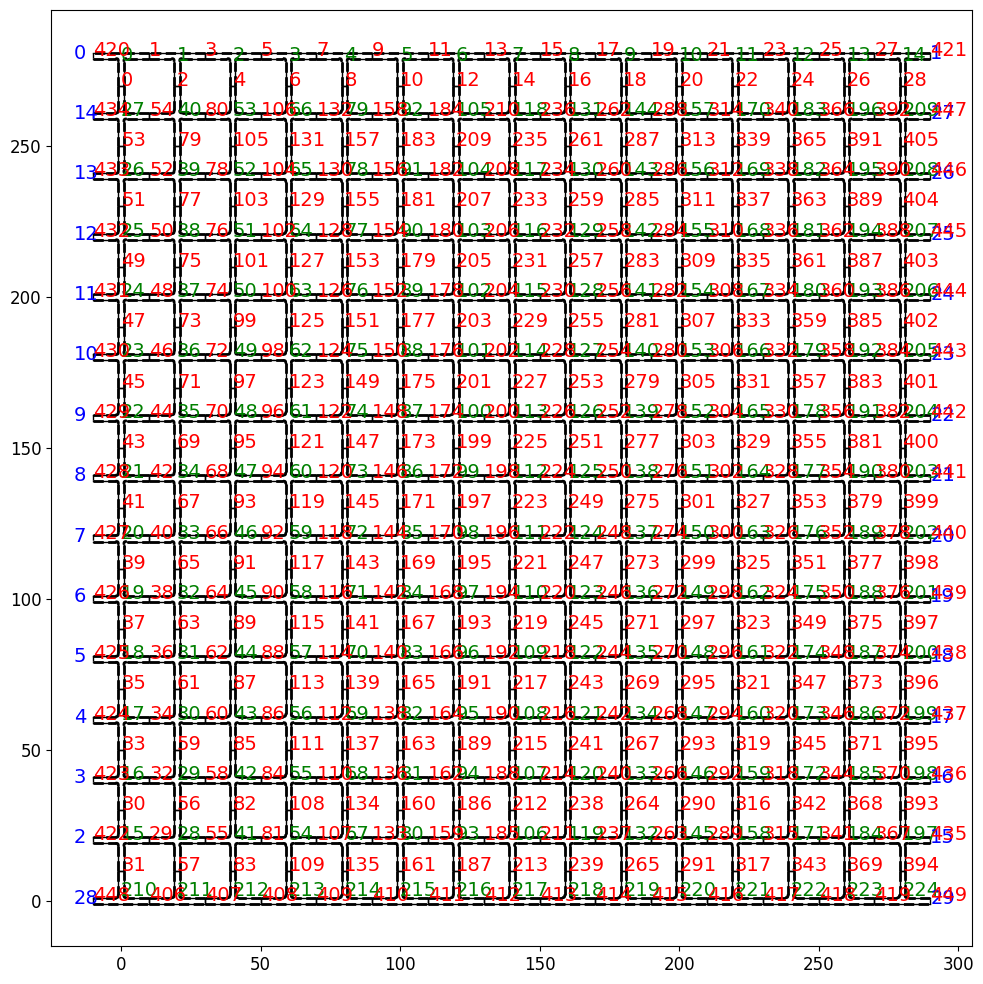

In [16]:

fig,ax = plt.subplots(figsize=(10,10), tight_layout=True)

for ip,p in enumerate(pipes):
    p.plot_plyg_bdr(ax, color='k')
    x = np.mean(p.xs)
    y = np.mean(p.ys)
    ax.text(x,y,f'{ip}',fontsize=14,color='g')
    
for i,blet in enumerate(boundary_lets):
    pos = np.array(blet['pos'])
    if pos[0] < 100:
        pos[0] -= 7
    pos[1] -= 1
    
    ax.text(pos[0],pos[1],f'{i}',fontsize=14,color='b')
    
for inode,node in enumerate(_nodes):
    ax.text(node['pos'][0],node['pos'][1],f'{inode}',fontsize=14,color='r')
    

In [17]:
nb = len(boundary_lets)
bflux = np.eye(nb)[0] - np.eye(nb)[-1]


#### solving the pipe system

In [18]:
flow_coef = flux_to_flow(bflux,verbose=True)

condition number of the system is : 4813.6772406995715
time taken is 0.004948749992763624 seconds


In [19]:
def pipe2baselet_idx(pidx):

    for inode,node in enumerate(_nodes):
        match node['node_type']:
            case 'internal':
                if node['let0'] == (pidx,0):
                    return inode
                elif node['let1'] == (pidx,0):
                    return inode
            case 'boundary':
                if node['let'] == (pidx,0):
                    return inode
            
            case _:
                raise ValueError(f'Unknown node type: {v["node_type"]}')
            
    raise ValueError(f"Pipe {pidx}'s baselet index not found")

#### solving for the velocity field

In [20]:
us = []
vs = []
ps = []
os = []
xs = []
ys = []

global_base_let_idx = pipe2baselet_idx(0)
for pidx,pipe in enumerate(pipes):
    
    # compute the pressure at the base let
    base_let_idx = pipe2baselet_idx(pidx)
    pressure_at_base_let = 0

    if base_let_idx != global_base_let_idx:
        # compute the pressure drop along the path
        path = nx.shortest_path(g, source=global_base_let_idx, target=base_let_idx)
        
        for edge in zip(path,path[1:]):
            pressure_at_base_let += np.dot(edges2pressure_drop[edge],flow_coef)
    
    
    # compute the local flow coefficients
    flow_idx = [i for i,(j,k) in flows if j==pidx]
    coef = flow_coef[flow_idx]
    
    # get the fields
    u,v,p,o = pipe.fields_with_fluxes(coef,0,pressure_at_base_let)
    
    us.append(u)
    vs.append(v)
    ps.append(p)
    os.append(o)
    xs.append(pipe.xs)
    ys.append(pipe.ys)
    
us = np.concatenate(us)
vs = np.concatenate(vs)
xs = np.concatenate(xs)
ys = np.concatenate(ys)
ps = np.concatenate(ps)
os = np.concatenate(os)

#### plotting the fields

In [21]:
axes

array([<Axes: >, <Axes: >], dtype=object)

In [ ]:
fig,axes = plt.subplots(2,1,figsize=(20,40),tight_layout=True)

for ax in axes:
    ax.set_aspect('equal')
    for ip,p in enumerate(pipes):
        c = np.array([np.mean(p.xs),np.mean(p.ys)])
        p.plot_plyg_bdr(ax, color='k')
        
cmap = 'viridis' # or 'cubehelix'
axes[0].set_title('velocity magnitude')
axes[1].set_title('pressure')

axes[0].scatter(xs,ys,c=np.sqrt(us**2+vs**2),s=1,cmap=cmap)
axes[1].scatter(xs,ys,c=-ps,s=1,cmap=cmap)

# fig.suptitle(f'A System of {n_rep_x} by {n_rep_y} Cross-Shaped Pipes. ', fontsize=18)

from mpl_toolkits.axes_grid1 import make_axes_locatable

for ax in axes:
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="3%", pad=0.05)
    plt.colorbar(ax.collections[0], cax=cax)

plt.savefig(f'demo_flux{n_rep_x} by {n_rep_y}.png')